# **Obtención y preparación de insumos**

**Datos para el modelo 2: digits**

Imágenes: (1797, 64)
Etiquetas: (1797,)
Clases: [0 1 2 3 4 5 6 7 8 9]
Rango de píxeles: 0.0 a 16.0


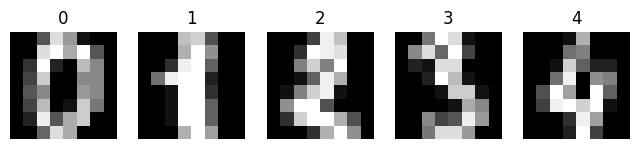

In [ ]:
from sklearn.datasets import load_digits # Dataset digits de scikit-learn
import numpy as np # Cálculos numéricos
import matplotlib.pyplot as plt # Gráficos

digits = load_digits() # Carga el dataset
X = digits.data # Imágenes aplanadas (64 valores por imagen)
y = digits.target # Etiquetas (dígito real, 0 a 9)

print("Imágenes:", X.shape) # Filas y columnas
print("Etiquetas:", y.shape) # Cantidad de etiquetas
print("Clases:", np.unique(y)) # Dígitos distintos
print("Rango de píxeles:", X.min(), "a", X.max()) # Valor mínimo y máximo

fig, axes = plt.subplots(1, 5, figsize=(8, 2)) # Espacio para 5 imágenes
for ax, img, lab in zip(axes, digits.images, y): # Recorre las primeras 5
    ax.imshow(img, cmap="gray") # Muestra la imagen en grises
    ax.set_title(lab) # Título: dígito real
    ax.axis("off") # Oculta los ejes
plt.show() # Muestra los gráficos

**Datos para el modelo 3: MNIST (scikit-learn)**

Imágenes: (70000, 784)
Etiquetas: (70000,)
Clases: [0 1 2 3 4 5 6 7 8 9]
Rango de píxeles: 0 a 255


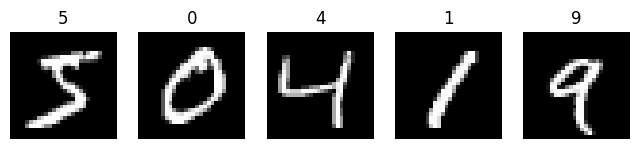

In [ ]:
from sklearn.datasets import fetch_openml # Descarga datasets desde OpenML

mnist = fetch_openml("mnist_784", version=1, as_frame=False) # Descarga MNIST
X_mnist = mnist.data # Imágenes aplanadas (784 valores por imagen)
y_mnist = mnist.target.astype(int) # Etiquetas como números enteros

print("Imágenes:", X_mnist.shape) # Filas y columnas
print("Etiquetas:", y_mnist.shape) # Cantidad de etiquetas
print("Clases:", np.unique(y_mnist)) # Dígitos distintos
print("Rango de píxeles:", X_mnist.min(), "a", X_mnist.max()) # Valor mínimo y máximo

fig, axes = plt.subplots(1, 5, figsize=(8, 2)) # Espacio para 5 imágenes
for ax, img, lab in zip(axes, X_mnist[:5], y_mnist[:5]): # Primeras 5 imágenes
    ax.imshow(img.reshape(28, 28), cmap="gray") # Devuelve la forma 28x28 y la muestra
    ax.set_title(lab) # Dígito real
    ax.axis("off") # Oculta los ejes
plt.show() # Muestra los gráficos

**Datos para el modelo 1: MNIST (Keras)**

In [ ]:
from tensorflow.keras.datasets import mnist # MNIST incluido en Keras

(X_train_cnn, y_train_cnn), (X_test_cnn, y_test_cnn) = mnist.load_data() # Ya viene separado en entrenamiento y prueba

print("Entrenamiento:", X_train_cnn.shape, y_train_cnn.shape) # Imágenes y etiquetas de entrenamiento
print("Prueba:", X_test_cnn.shape, y_test_cnn.shape) # Imágenes y etiquetas de prueba
print("Rango de píxeles:", X_train_cnn.min(), "a", X_train_cnn.max()) # Valor mínimo y máximo

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Entrenamiento: (60000, 28, 28) (60000,)
Prueba: (10000, 28, 28) (10000,)
Rango de píxeles: 0 a 255


In [ ]:
print("Nulos en digits:", np.isnan(X).sum()) # Valores nulos en digits
print("Nulos en MNIST (scikit-learn):", np.isnan(X_mnist).sum()) # Valores nulos en MNIST de scikit-learn
print("Nulos en MNIST (Keras):", np.isnan(X_train_cnn).sum()) # Valores nulos en MNIST de Keras

print("\nImágenes por dígito (digits):", np.bincount(y)) # Cantidad por clase
print("Imágenes por dígito (MNIST scikit-learn):", np.bincount(y_mnist)) # Cantidad por clase
print("Imágenes por dígito (MNIST Keras):", np.bincount(y_train_cnn)) # Cantidad por clase

Nulos en digits: 0
Nulos en MNIST (scikit-learn): 0
Nulos en MNIST (Keras): 0

Imágenes por dígito (digits): [178 182 177 183 181 182 181 179 174 180]
Imágenes por dígito (MNIST scikit-learn): [6903 7877 6990 7141 6824 6313 6876 7293 6825 6958]
Imágenes por dígito (MNIST Keras): [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


In [ ]:
from sklearn.model_selection import train_test_split # Separa entrenamiento y prueba

X_d = X / 16.0 # digits: píxeles a escala 0-1 (el máximo es 16)
X_d_train, X_d_test, y_d_train, y_d_test = train_test_split(X_d, y, test_size=0.2, random_state=42, stratify=y) # 80% entrenamiento, 20% prueba

X_m, _, y_m, _ = train_test_split(X_mnist, y_mnist, train_size=10000, random_state=42, stratify=y_mnist) # MNIST scikit-learn: toma un subconjunto de 10 000
X_m = X_m / 255.0 # Píxeles a escala 0-1 (el máximo es 255)
X_m_train, X_m_test, y_m_train, y_m_test = train_test_split(X_m, y_m, test_size=0.2, random_state=42, stratify=y_m) # 80% entrenamiento, 20% prueba

X_train_cnn = X_train_cnn / 255.0 # MNIST Keras: normaliza entrenamiento
X_test_cnn = X_test_cnn / 255.0 # Normaliza prueba
X_train_cnn = X_train_cnn.reshape(-1, 28, 28, 1) # Agrega el canal (escala de grises)
X_test_cnn = X_test_cnn.reshape(-1, 28, 28, 1) # Agrega el canal en prueba

print("digits:", X_d_train.shape, X_d_test.shape, "| máximo:", X_d.max()) # Formas y máximo
print("MNIST scikit-learn:", X_m_train.shape, X_m_test.shape, "| máximo:", X_m.max()) # Formas y máximo
print("CNN:", X_train_cnn.shape, X_test_cnn.shape, "| máximo:", X_train_cnn.max()) # Formas y máximo

digits: (1437, 64) (360, 64) | máximo: 1.0
MNIST scikit-learn: (8000, 784) (2000, 784) | máximo: 1.0
CNN: (60000, 28, 28, 1) (10000, 28, 28, 1) | máximo: 1.0


digits | Media: 0.305 | Desv. estándar: 0.376 | Píxeles en 0: 48.9 %
MNIST scikit-learn | Media: 0.131 | Desv. estándar: 0.309 | Píxeles en 0: 80.8 %
MNIST Keras | Media: 0.131 | Desv. estándar: 0.308 | Píxeles en 0: 80.9 %


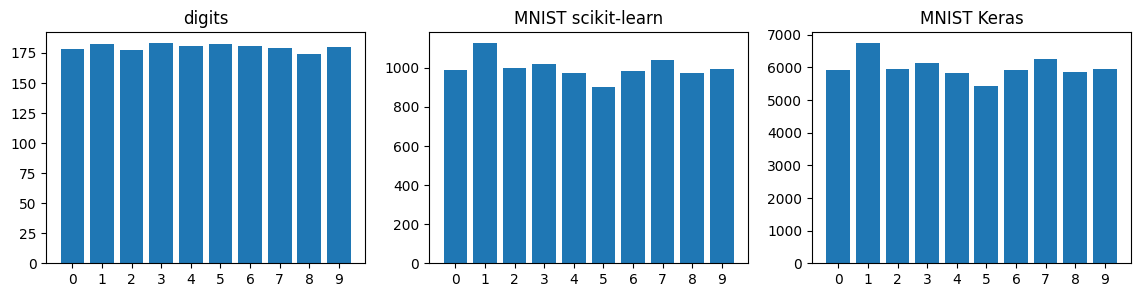

In [ ]:
datos = {"digits": (X_d, y), "MNIST scikit-learn": (X_m, y_m), "MNIST Keras": (X_train_cnn.reshape(len(X_train_cnn), -1), y_train_cnn)} # Los 3 datasets ya normalizados

for nombre, (A, b) in datos.items(): # Recorre cada dataset
    print(nombre, "| Media:", round(A.mean(), 3), "| Desv. estándar:", round(A.std(), 3), "| Píxeles en 0:", round((A == 0).mean() * 100, 1), "%") # Indicadores

fig, axes = plt.subplots(1, 3, figsize=(14, 3)) # Espacio para 3 gráficos
for ax, (nombre, (A, b)) in zip(axes, datos.items()): # Uno por dataset
    ax.bar(range(10), np.bincount(b)) # Cantidad de imágenes por dígito
    ax.set_title(nombre) # Título del gráfico
    ax.set_xticks(range(10)) # Dígitos del 0 al 9
plt.show() # Muestra los gráficos

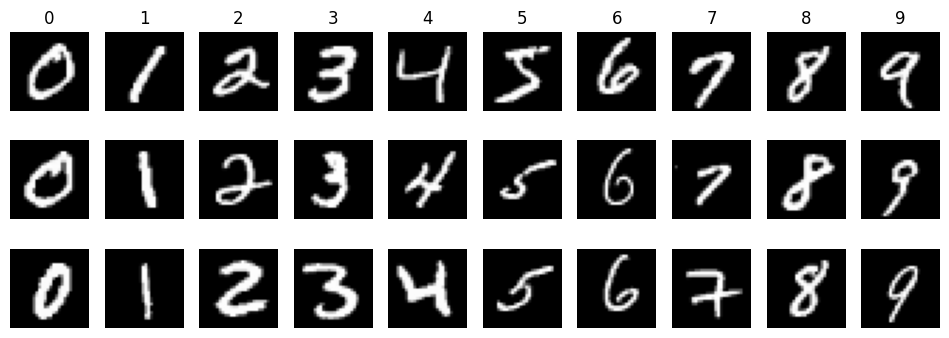

In [ ]:
fig, axes = plt.subplots(3, 10, figsize=(12, 4)) # 3 filas x 10 dígitos
for d in range(10): # Un dígito por columna
    ejemplos = np.where(y_train_cnn == d)[0][:3] # Primeros 3 ejemplos del dígito d
    for fila, idx in enumerate(ejemplos): # Una fila por ejemplo
        axes[fila, d].imshow(X_train_cnn[idx].squeeze(), cmap="gray") # Muestra la imagen
        axes[fila, d].axis("off") # Oculta los ejes
        if fila == 0: axes[fila, d].set_title(d) # Título: dígito real
plt.show() # Muestra los gráficos

# Modelo 2: scikit-learn con digits (KNN y SVM)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier # Modelo KNN
from sklearn.svm import SVC # Modelo SVM
from sklearn.model_selection import GridSearchCV # Validación cruzada y ajuste de hiperparámetros

knn_d = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": [1, 3, 5, 7]}, cv=5) # Prueba distintos valores de k
knn_d.fit(X_d_train, y_d_train) # Entrena y busca el mejor k

svm_d = GridSearchCV(SVC(), {"C": [1, 10], "gamma": ["scale", 0.01]}, cv=5) # Prueba combinaciones de C y gamma
svm_d.fit(X_d_train, y_d_train) # Entrena y busca la mejor combinación

print("KNN mejor parámetro:", knn_d.best_params_, "| Validación cruzada:", round(knn_d.best_score_, 4)) # Resultado KNN
print("SVM mejor parámetro:", svm_d.best_params_, "| Validación cruzada:", round(svm_d.best_score_, 4)) # Resultado SVM

KNN mejor parámetro: {'n_neighbors': 1} | Validación cruzada: 0.9902
SVM mejor parámetro: {'C': 10, 'gamma': 'scale'} | Validación cruzada: 0.9889


# Modelo 3: scikit-learn con MNIST (KNN y SVM)

In [ ]:
knn_m = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": [3, 5]}, cv=3) # Prueba 2 valores de k (3 partes para ir más rápido)
knn_m.fit(X_m_train, y_m_train) # Entrena y busca el mejor k

svm_m = GridSearchCV(SVC(gamma="scale"), {"C": [1, 10]}, cv=3) # Prueba 2 valores de C
svm_m.fit(X_m_train, y_m_train) # Entrena y busca el mejor C

print("KNN mejor parámetro:", knn_m.best_params_, "| Validación cruzada:", round(knn_m.best_score_, 4)) # Resultado KNN
print("SVM mejor parámetro:", svm_m.best_params_, "| Validación cruzada:", round(svm_m.best_score_, 4)) # Resultado SVM


KNN mejor parámetro: {'n_neighbors': 5} | Validación cruzada: 0.9379
SVM mejor parámetro: {'C': 10} | Validación cruzada: 0.9575


# Modelo 1: red neuronal convolucional (CNN).

In [ ]:
from tensorflow.keras.models import Sequential # Modelo secuencial
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense # Capas de la red

cnn = Sequential([
    Input(shape=(28, 28, 1)), # Entrada: imagen 28x28 en grises
    Conv2D(16, (3, 3), activation="relu"), # Bloque 1: detecta bordes y trazos
    MaxPooling2D((2, 2)), # Reduce el tamaño de la imagen
    Conv2D(32, (3, 3), activation="relu"), # Bloque 2: detecta combinaciones de trazos
    MaxPooling2D((2, 2)), # Reduce nuevamente
    Flatten(), # Convierte el mapa 2D en una lista de números
    Dense(64, activation="relu"), # Capa densa oculta
    Dense(10, activation="softmax") # Salida: probabilidad de cada dígito (0 al 9)
]) # Fin de la arquitectura

cnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]) # Optimizador, pérdida y métrica
cnn.summary() # Muestra la arquitectura

historia = cnn.fit(X_train_cnn, y_train_cnn, epochs=5, batch_size=128, validation_split=0.2, verbose=1) # Entrena 5 épocas

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,714 (221.54 KB)

 Trainable params: 56,714 (221.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.9033 - loss: 0.3414 - val_accuracy: 0.9697 - val_loss: 0.1071
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9725 - loss: 0.0896 - val_accuracy: 0.9783 - val_loss: 0.0750
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9799 - loss: 0.0653 - val_accuracy: 0.9796 - val_loss: 0.0698
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9845 - loss: 0.0507 - val_accuracy: 0.9850 - val_loss: 0.0545
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9874 - loss: 0.0418 - val_accuracy: 0.9862 - val_loss: 0.0491


In [ ]:
import pandas as pd # Para armar la tabla
from sklearn.metrics import accuracy_score # Métrica Accuracy

resultados = pd.DataFrame({ # Tabla comparativa
    "Modelo": ["2: KNN", "2: SVM", "3: KNN", "3: SVM", "1: CNN"], # Nombre de cada modelo
    "Datos": ["digits", "digits", "MNIST scikit-learn", "MNIST scikit-learn", "MNIST Keras"], # Dataset usado
    "Accuracy en test": [
        accuracy_score(y_d_test, knn_d.predict(X_d_test)), # KNN con digits
        accuracy_score(y_d_test, svm_d.predict(X_d_test)), # SVM con digits
        accuracy_score(y_m_test, knn_m.predict(X_m_test)), # KNN con MNIST scikit-learn
        accuracy_score(y_m_test, svm_m.predict(X_m_test)), # SVM con MNIST scikit-learn
        cnn.evaluate(X_test_cnn, y_test_cnn, verbose=0)[1] # CNN con MNIST Keras
    ]
}) # Fin de la tabla

resultados["Accuracy en test"] = resultados["Accuracy en test"].round(4) # Redondea a 4 decimales
print(resultados) # Muestra la tabla

   Modelo               Datos  Accuracy en test
0  2: KNN              digits            0.9861
1  2: SVM              digits            0.9944
2  3: KNN  MNIST scikit-learn            0.9435
3  3: SVM  MNIST scikit-learn            0.9645
4  1: CNN         MNIST Keras            0.9861


              precision    recall  f1-score   support

           0     0.9878    0.9939    0.9908       980
           1     0.9921    0.9938    0.9930      1135
           2     0.9864    0.9855    0.9859      1032
           3     0.9872    0.9960    0.9916      1010
           4     0.9948    0.9766    0.9856       982
           5     0.9854    0.9865    0.9860       892
           6     0.9823    0.9875    0.9849       958
           7     0.9768    0.9844    0.9806      1028
           8     0.9916    0.9743    0.9829       974
           9     0.9763    0.9812    0.9787      1009

    accuracy                         0.9861     10000
   macro avg     0.9861    0.9860    0.9860     10000
weighted avg     0.9861    0.9861    0.9861     10000



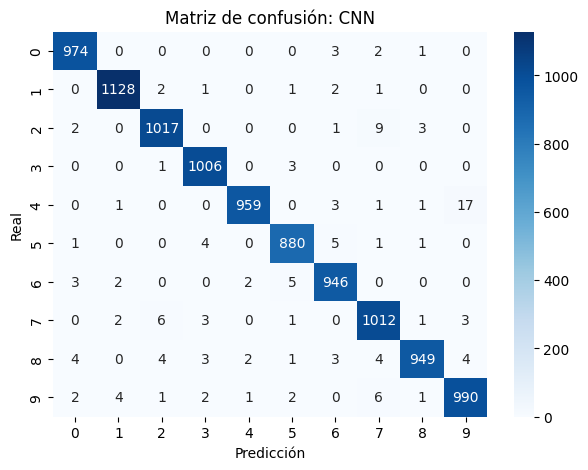

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report # Métricas de evaluación
import seaborn as sns # Gráficos

pred_cnn = np.argmax(cnn.predict(X_test_cnn, verbose=0), axis=1) # Predicciones de la CNN (dígito más probable)
print(classification_report(y_test_cnn, pred_cnn, digits=4)) # Precisión, recall y F1 por dígito

plt.figure(figsize=(7, 5)) # Tamaño del gráfico
sns.heatmap(confusion_matrix(y_test_cnn, pred_cnn), annot=True, fmt="d", cmap="Blues") # Matriz de confusión
plt.xlabel("Predicción") # Eje X
plt.ylabel("Real") # Eje Y
plt.title("Matriz de confusión: CNN") # Título
plt.show() # Muestra el gráfico

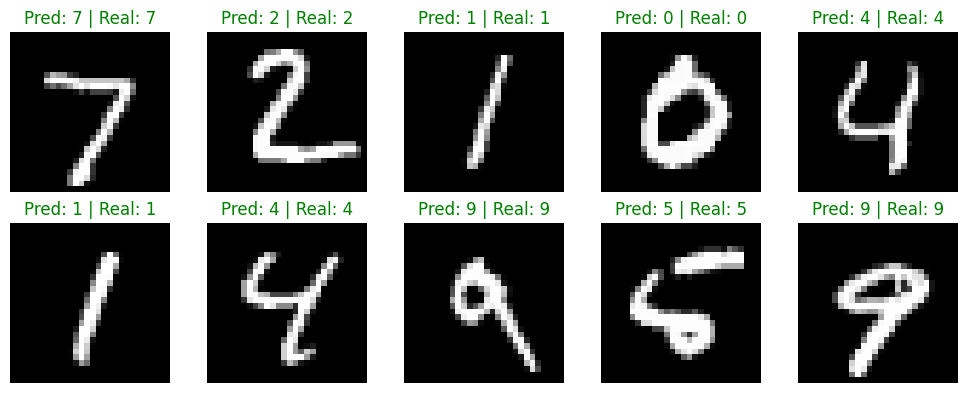

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4)) # 2 filas x 5 imágenes
for i, ax in enumerate(axes.ravel()): # Primeras 10 imágenes de prueba
    ax.imshow(X_test_cnn[i].squeeze(), cmap="gray") # Muestra la imagen
    color = "green" if pred_cnn[i] == y_test_cnn[i] else "red" # Verde si acierta, rojo si falla
    ax.set_title(f"Pred: {pred_cnn[i]} | Real: {y_test_cnn[i]}", color=color) # Predicción frente a real
    ax.axis("off") # Oculta los ejes
plt.tight_layout() # Ajusta los espacios
plt.show() # Muestra el gráfico

In [ ]:
import tensorflow as tf # Para ver la versión
from google.colab import files # Para descargar archivos

cnn.save("modelo_cnn.keras") # Guarda la CNN entrenada en un archivo
print("Versión de TensorFlow:", tf.__version__) # La necesitaremos para el servidor
files.download("modelo_cnn.keras") # Descarga el archivo a tu computadora

Versión de TensorFlow: 2.21.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>